In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/bank_note_dataset.csv")

In [3]:
def remove_all_outliers_from_column(df,threshold=1.5):
    df_clean = df.copy()
    numeric_cols = df.select_dtypes(include=["float64","int64"]).columns

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        df_clean = df_clean[ (df_clean[col] >= lower_bound) &  (df_clean[col] <= upper_bound)]

    return df_clean.copy()

In [4]:
df_new = remove_all_outliers_from_column(df)

In [5]:
X = df_new.drop("Class",axis=1)
y = df_new["Class"]

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.21,random_state=15)

In [10]:
from sklearn.preprocessing import StandardScaler

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.naive_bayes import GaussianNB

def evulate_model(true,predicted):
    score = accuracy_score(true,predicted)
    matrix = confusion_matrix(true,predicted)
    report = classification_report(true,predicted)

    return score,matrix,report

models = {
    "Logistic Regression": LogisticRegression(),
    "K Neighbors Classifier": KNeighborsClassifier(),
    "SVC": SVC(),
    "Decision Tree Classifier": DecisionTreeClassifier(),
    "Random Forest Classifier": RandomForestClassifier(),
    "AdaBoost Classifier": AdaBoostClassifier(),
    "Gradient Boost Classifier": GradientBoostingClassifier(),
    "Gaussian NB": GaussianNB(),
    "XGBoost Classifier": xgb.XGBClassifier(),
    "LightGBM CLassifier": lgb.LGBMClassifier()
}

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train,y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_score,model_train_matrix,model_train_report = evulate_model(y_train,y_train_pred)
    model_test_score,model_test_matrix,model_test_report = evulate_model(y_test,y_test_pred)

    print(list(models.keys())[i])
    print("Model performance for Traning set")
    print("Score",model_train_score)
    print("Matrix",model_train_matrix)
    print("Report",model_train_report)

    print("---------------------------------")

    print("Model performance for Test set")
    print("Score",model_test_score)
    print("Matrix",model_test_matrix)
    print("Report",model_test_report)
    print("\n")

Logistic Regression
Model performance for Traning set
Score 0.982779827798278
Matrix [[453  13]
 [  1 346]]
Report               precision    recall  f1-score   support

           0       1.00      0.97      0.98       466
           1       0.96      1.00      0.98       347

    accuracy                           0.98       813
   macro avg       0.98      0.98      0.98       813
weighted avg       0.98      0.98      0.98       813

---------------------------------
Model performance for Test set
Score 0.9861751152073732
Matrix [[125   3]
 [  0  89]]
Report               precision    recall  f1-score   support

           0       1.00      0.98      0.99       128
           1       0.97      1.00      0.98        89

    accuracy                           0.99       217
   macro avg       0.98      0.99      0.99       217
weighted avg       0.99      0.99      0.99       217



K Neighbors Classifier
Model performance for Traning set
Score 0.998769987699877
Matrix [[465   1]
 [ 

In [14]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for i in range(len(list(models))):

    model = list(models.values())[i]

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    print(list(models.keys())[i])
    print("---------------------------------")

    print(
        "Accuracy:",
        scores["test_accuracy"].mean()
    )

    print(
        "F1:",
        scores["test_f1"].mean()
    )

    print(
        "ROC-AUC:",
        scores["test_roc_auc"].mean()
    )

    print("\n")

Logistic Regression
---------------------------------
Accuracy: 0.9815572218435203
F1: 0.9788769266645236
ROC-AUC: 0.9999064983637214


K Neighbors Classifier
---------------------------------
Accuracy: 0.9963190184049079
F1: 0.9958041958041959
ROC-AUC: 0.9989247311827956


SVC
---------------------------------
Accuracy: 1.0
F1: 1.0
ROC-AUC: 1.0


Decision Tree Classifier
---------------------------------
Accuracy: 0.9778686662122243
F1: 0.9740143284468964
ROC-AUC: 0.9770407584716321


Random Forest Classifier
---------------------------------
Accuracy: 0.9901764750435508
F1: 0.9885705600509531
ROC-AUC: 0.999631222725729


AdaBoost Classifier
---------------------------------
Accuracy: 0.9926304627736119
F1: 0.991427702908096
ROC-AUC: 0.9991927692067945


Gradient Boost Classifier
---------------------------------
Accuracy: 0.990153752934939
F1: 0.9884012545016038
ROC-AUC: 0.9995066675571584


Gaussian NB
---------------------------------
Accuracy: 0.8560630159812165
F1: 0.829508965053

In [16]:
pd.DataFrame( X_train).corrwith(y_train).sort_values(ascending=False)

3    0.030972
2    0.026003
0    0.006795
1   -0.011445
dtype: float64

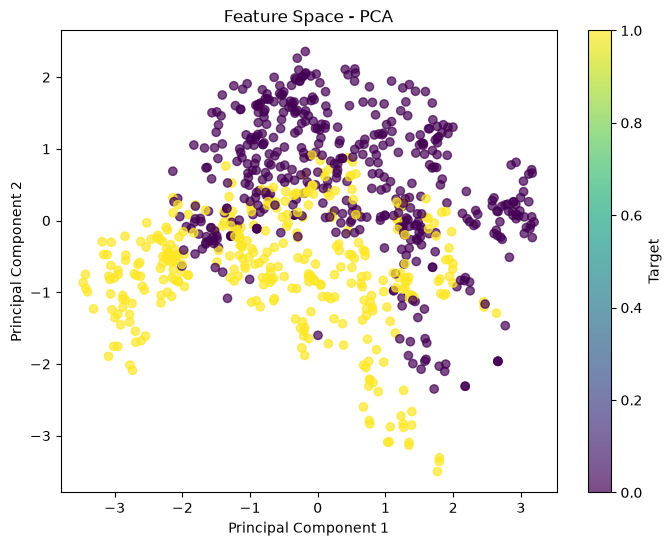

In [17]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Feature Space - PCA")
plt.colorbar(label="Target")

plt.show()

In [18]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.57550976 0.2856176 ]

Total Explained Variance:
0.8611273616946247


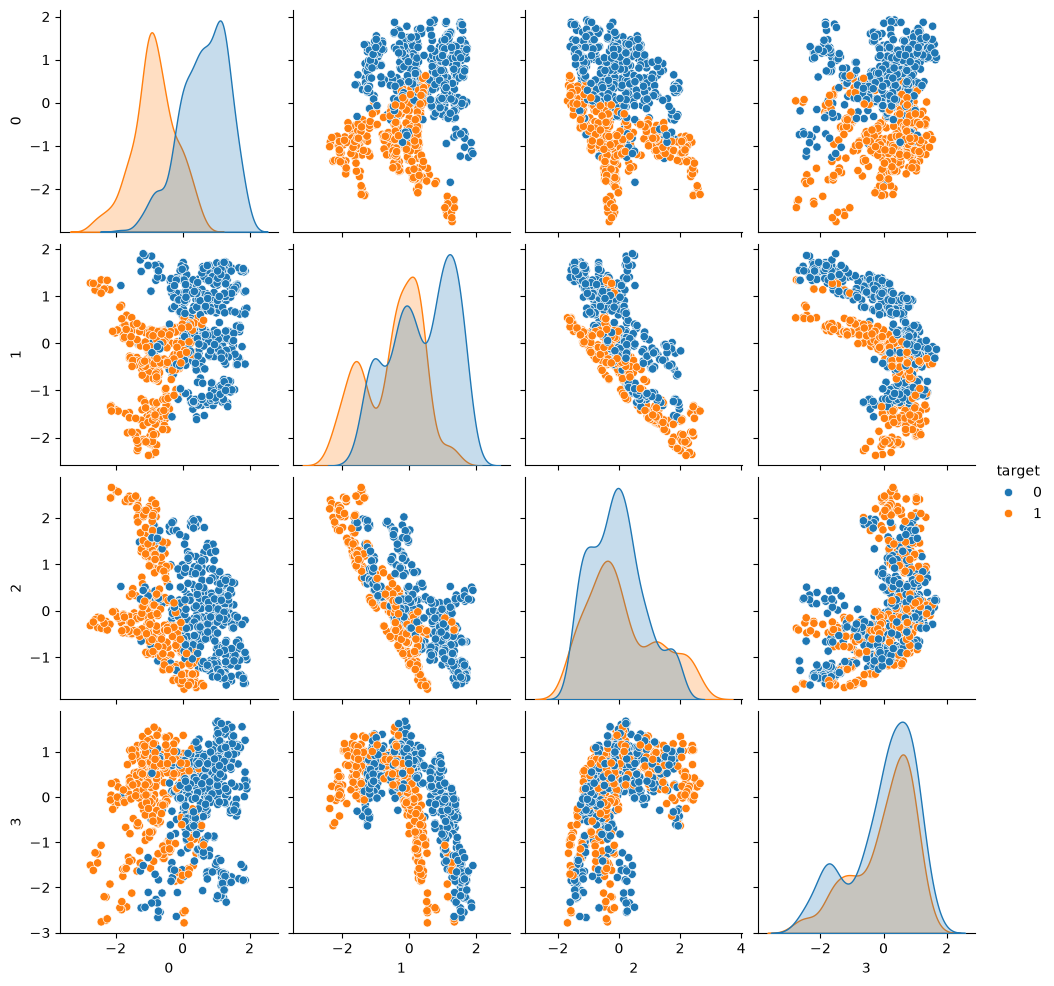

In [21]:
df_plot = pd.DataFrame(X_train).copy()
df_plot["target"] = y_train.values

sns.pairplot(
    df_plot,
    hue="target"
)

plt.show()

In [22]:
svc_params = {
    "C": [0.01, 0.1, 1, 10, 100, 1000],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "kernel": ["rbf", "linear", "poly", "sigmoid"]
}

In [23]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.svm import SVC

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=SVC(),
    param_distributions=svc_params,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV F1:")
print(random_search.best_score_)

Best Parameters:
{'kernel': 'rbf', 'gamma': 0.01, 'C': 1000}

Best CV F1:
1.0


In [24]:
best_svc = random_search.best_estimator_

print(best_svc)

SVC(C=1000, gamma=0.01)


In [25]:
y_test_pred = best_svc.predict(X_test)

test_score, test_matrix, test_report = evulate_model(
    y_test,
    y_test_pred
)

print("Test Accuracy:", test_score)
print("\nConfusion Matrix:")
print(test_matrix)
print("\nClassification Report:")
print(test_report)

Test Accuracy: 1.0

Confusion Matrix:
[[128   0]
 [  0  89]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       128
           1       1.00      1.00      1.00        89

    accuracy                           1.00       217
   macro avg       1.00      1.00      1.00       217
weighted avg       1.00      1.00      1.00       217



In [26]:
# WHAT IS THIS am i getting data leakage i even check X for "does it include target feature also" pls help me on comments for this one